<a href="https://colab.research.google.com/github/AndresAvella09/Proyecto_Multimodal/blob/main/notebooks/09_buscador_semantico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09 · Buscador semántico de películas (paso 1: sin entrenar)

**Qué hace:** escribes una descripción ("una casa embrujada en la nieve", "a robot in space") y devuelve
el **póster y el título** de las películas que mejor coinciden. Funciona en **español e inglés**.

**Cómo funciona, en una frase:** CLIP pone textos e imágenes en el **mismo espacio de vectores**.
La frase de búsqueda se convierte en un vector y se buscan los pósters (o sinopsis) cuyo vector está más cerca
(similitud coseno). Es la *búsqueda semántica* de la sesión 10 del curso.

| Sección | Qué hace |
|---|---|
| 1 | Carga títulos, años, géneros y los vectores del notebook 03 |
| 2 | Guarda los pósters en miniatura en Drive (solo la primera vez) |
| 3 | Carga los dos codificadores de texto: **CLIP multilingüe** (español + inglés) y **CLIP original** (solo inglés) |
| 4 | La función `buscar`: por **póster**, por **sinopsis** o por **ambos** |
| 5 | Prueba libre (escribe tu búsqueda) y comparación de los tres modos |
| 6 | ¿Da lo mismo buscar en español que en inglés? |



In [ ]:
import os, sys, io, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip install -q sentence-transformers

BASE = os.environ.get('PM_BASE', '/content/drive/MyDrive/proyecto_multimodal')
DATA, EMB = f'{BASE}/data', f'{BASE}/embeddings'

pelis = pd.read_parquet(f'{DATA}/mmimdb_con_anio.parquet')       # notebook 05
assert (pelis['fila_hdf5'].values == np.arange(len(pelis))).all(), 'debe estar en orden del HDF5'
GENEROS = [c for c in pelis.columns if c.startswith('hoy_')]
GENEROS = [g[4:] for g in GENEROS]

def l2(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True).clip(min=1e-8)

# Vectores del notebook 03, normalizados: así el producto punto ES la similitud coseno
V_POSTER = l2(np.load(f'{EMB}/clip_img.npy').astype(np.float32))
V_SINOPSIS = l2(np.load(f'{EMB}/clip_txt.npy').astype(np.float32))
assert len(V_POSTER) == len(V_SINOPSIS) == len(pelis)

pelis['titulo'] = pelis['titulo'].fillna('(sin título)')
pelis['anio_txt'] = pelis['anio'].astype('Int64').astype(str).replace('<NA>', '?')
print(f'{len(pelis):,} películas | vectores póster {V_POSTER.shape} | sinopsis {V_SINOPSIS.shape}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
25,959 películas | vectores póster (25959, 512) | sinopsis (25959, 512)


## 2. Pósters en miniatura

Para mostrar los resultados hacen falta las imágenes. Están dentro del HDF5 de MM-IMDB (15 GB), así que
**la primera vez** se extraen todas como JPEG pequeños (120×192) y se guardan en un solo archivo en Drive
(~150 MB). Las siguientes veces solo se carga ese archivo.

Este mismo archivo servirá después para la página web.

In [ ]:
from PIL import Image

RUTA_MINI = f'{DATA}/posters_mini.parquet'
TAM_MINI = (120, 192)   # ancho, alto (los pósters de MM-IMDB son 160x256)

def poster_a_rgb(img):
    # (3, 256, 160) en formato VGG (BGR, media restada) -> (256, 160, 3) RGB uint8  [igual que notebooks 01 y 03]
    medias_bgr = np.array([103.939, 116.779, 123.68], dtype=np.float32)[:, None, None]
    rgb = (img.astype(np.float32) + medias_bgr)[::-1]
    return np.clip(np.rint(np.transpose(rgb, (1, 2, 0))), 0, 255).astype(np.uint8)

def a_jpg(rgb):
    buf = io.BytesIO()
    Image.fromarray(rgb).resize(TAM_MINI, Image.LANCZOS).save(buf, format='JPEG', quality=82)
    return buf.getvalue()

if os.path.exists(RUTA_MINI):
    mini = pd.read_parquet(RUTA_MINI)
    print(f'Miniaturas cargadas: {len(mini):,}')
else:
    import kagglehub, h5py
    ruta = kagglehub.dataset_download('johnarevalo/mmimdb')
    f = h5py.File(os.path.join(ruta, 'multimodal_imdb.hdf5'), 'r')
    jpgs = []
    for a in range(0, len(pelis), 512):
        jpgs += [a_jpg(poster_a_rgb(x)) for x in f['images'][a:a + 512]]
        if (a // 512) % 10 == 0:
            print(f'{min(a + 512, len(pelis)):,}/{len(pelis):,}')
    mini = pd.DataFrame({'fila_hdf5': np.arange(len(jpgs)), 'jpg': jpgs})
    mini.to_parquet(RUTA_MINI, index=False)
    print(f'Guardado {RUTA_MINI} ({os.path.getsize(RUTA_MINI) / 1e6:.0f} MB)')

assert len(mini) == len(pelis)
POSTERS = mini['jpg'].tolist()

def ver_poster(i):
    return Image.open(io.BytesIO(POSTERS[i]))

100%|██████████| 3.65G/3.65G [01:03<00:00, 61.7MB/s]

Extracting files...


512/25,959
5,632/25,959
10,752/25,959
15,872/25,959
20,992/25,959
25,959/25,959
Guardado /content/drive/MyDrive/proyecto_multimodal/data/posters_mini.parquet (211 MB)


## 3. Los codificadores de texto

| Codificador | Idiomas | Qué es |
|---|---|---|
| `multi` | español, inglés y 50+ idiomas | [CLIP multilingüe](https://huggingface.co/sentence-transformers/clip-ViT-B-32-multilingual-v1): un DistilBERT multilingüe entrenado para **imitar** al codificador de texto de CLIP |
| `clip` | inglés | El codificador de texto original de CLIP ViT-B/32 (el mismo del notebook 03) |

Los dos producen vectores de 512 números **en el mismo espacio que los pósters**, así que se comparan
directamente con `clip_img.npy`. El multilingüe es el que usará la página web; el original sirve de referencia
para ver cuánto se pierde con la versión multilingüe.

In [ ]:
import torch
from sentence_transformers import SentenceTransformer
from transformers import CLIPModel, CLIPTokenizer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
CLIP_ID = 'openai/clip-vit-base-patch32'

modelo_multi = SentenceTransformer('sentence-transformers/clip-ViT-B-32-multilingual-v1', device=device)
clip = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
tok_clip = CLIPTokenizer.from_pretrained(CLIP_ID)

@torch.no_grad()
def _clip_texto(textos):
    enc = tok_clip(textos, padding=True, truncation=True, max_length=77, return_tensors='pt').to(device)
    pooled = clip.text_model(**enc).pooler_output
    return clip.text_projection(pooled).float().cpu().numpy()

def codificar(textos, encoder='multi'):
    # lista de frases -> (n, 512) normalizados, en el espacio de CLIP
    if encoder == 'multi':
        v = modelo_multi.encode(textos, convert_to_numpy=True)
    elif encoder == 'clip':
        v = _clip_texto(textos)
    else:
        raise ValueError("encoder debe ser 'multi' o 'clip'")
    return l2(v.astype(np.float32))

print('Codificadores listos en', device)

modules.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.65k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  539MB            

... (18 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Codificadores listos en cpu


In [ ]:
# Chequeo: la misma idea en dos idiomas debe quedar muy cerca; ideas distintas, más lejos
frases = ['una película de terror', 'a horror movie', 'una comedia romántica', 'a romantic comedy']
v = codificar(frases, 'multi')
sim = pd.DataFrame(v @ v.T, index=frases, columns=frases).round(2)
print('Similitud coseno entre frases (CLIP multilingüe):')
print(sim.to_string())

# ¿Cuánto se parece el multilingüe al original en inglés? (1 = idénticos)
en = ['a horror movie', 'a robot in space', 'two cowboys in the desert']
print('\nMultilingüe vs. original (mismas frases en inglés):',
      np.round((codificar(en, 'multi') * codificar(en, 'clip')).sum(1), 2))

Similitud coseno entre frases (CLIP multilingüe):
                        una película de terror  a horror movie  una comedia romántica  a romantic comedy
una película de terror                    1.00            0.99                   0.94               0.94
a horror movie                            0.99            1.00                   0.93               0.92
una comedia romántica                     0.94            0.93                   1.00               1.00
a romantic comedy                         0.94            0.92                   1.00               1.00

Multilingüe vs. original (mismas frases en inglés): [0.98 0.98 0.98]


## 4. La función `buscar`

Tres modos:

- **`poster`**: compara la frase con el vector de cada **póster**. Busca por lo que se *ve*.
- **`sinopsis`**: compara la frase con el vector de cada **sinopsis**. Busca por lo que se *cuenta*.
- **`ambos`**: combina los dos puntajes.

**Detalle importante para `ambos`:** los puntajes de los dos modos no están en la misma escala.
Texto contra texto da similitudes más altas que texto contra imagen (es la *brecha modal* de CLIP:
imágenes y textos ocupan zonas distintas del espacio). Si se suman tal cual, la sinopsis domina siempre,
el mismo desbalance que estudia el proyecto. Por eso, antes de combinar, cada puntaje se **estandariza**
(z-score sobre todo el catálogo, para esa búsqueda) y luego se promedia con un peso `alfa`:

$$\text{puntaje} = \alpha \cdot z_{\text{póster}} + (1 - \alpha) \cdot z_{\text{sinopsis}}$$

In [ ]:
def buscar(consulta, modo='ambos', k=10, alfa=0.5, encoder='multi', solo_cine=True):
    # Devuelve un DataFrame con las k películas más parecidas a la consulta
    q = codificar([consulta], encoder)[0]
    s_poster, s_sinopsis = V_POSTER @ q, V_SINOPSIS @ q            # similitud coseno con todo el catálogo

    if modo == 'poster':
        puntaje = s_poster
    elif modo == 'sinopsis':
        puntaje = s_sinopsis
    elif modo == 'ambos':
        z = lambda s: (s - s.mean()) / (s.std() + 1e-8)
        puntaje = alfa * z(s_poster) + (1 - alfa) * z(s_sinopsis)
    else:
        raise ValueError("modo debe ser 'poster', 'sinopsis' o 'ambos'")

    if solo_cine:   # dejar fuera telefilmes, videos, episodios... (columna del notebook 05)
        puntaje = np.where(pelis['es_pelicula'].fillna(False).values, puntaje, -np.inf)

    top = np.argsort(-puntaje)[:k]
    res = pelis.iloc[top][['fila_hdf5', 'titulo', 'anio_txt', 'generos_imdb_hoy']].copy()
    res['puntaje'] = puntaje[top]
    res['cos_poster'], res['cos_sinopsis'] = s_poster[top], s_sinopsis[top]
    return res.reset_index(drop=True)


def mostrar(res, titulo='', columnas=5):
    filas = int(np.ceil(len(res) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(2.3 * columnas, 4.4 * filas))
    for ax in np.atleast_1d(axes).flat:
        ax.axis('off')
    for ax, (_, r) in zip(np.atleast_1d(axes).flat, res.iterrows()):
        ax.imshow(ver_poster(int(r['fila_hdf5'])))
        nombre = r['titulo'] if len(r['titulo']) <= 24 else r['titulo'][:22] + '…'
        ax.set_title(f"{nombre}\n({r['anio_txt']})", fontsize=8)
    if titulo:
        fig.suptitle(titulo, fontsize=11)
    plt.tight_layout(h_pad=2.0); plt.show()


# Escala de los puntajes: por qué hace falta estandarizar en el modo 'ambos'
q = codificar(['a horror movie'])[0]
print(f"Similitud con pósters:  media {np.mean(V_POSTER @ q):.3f} | máx {np.max(V_POSTER @ q):.3f}")
print(f"Similitud con sinopsis: media {np.mean(V_SINOPSIS @ q):.3f} | máx {np.max(V_SINOPSIS @ q):.3f}")

Similitud con pósters:  media 0.211 | máx 0.308
Similitud con sinopsis: media 0.771 | máx 0.928


## 5. Prueba el buscador

Escribe una búsqueda en el formulario (en Colab aparece como una caja de texto a la derecha) y ejecuta la celda.

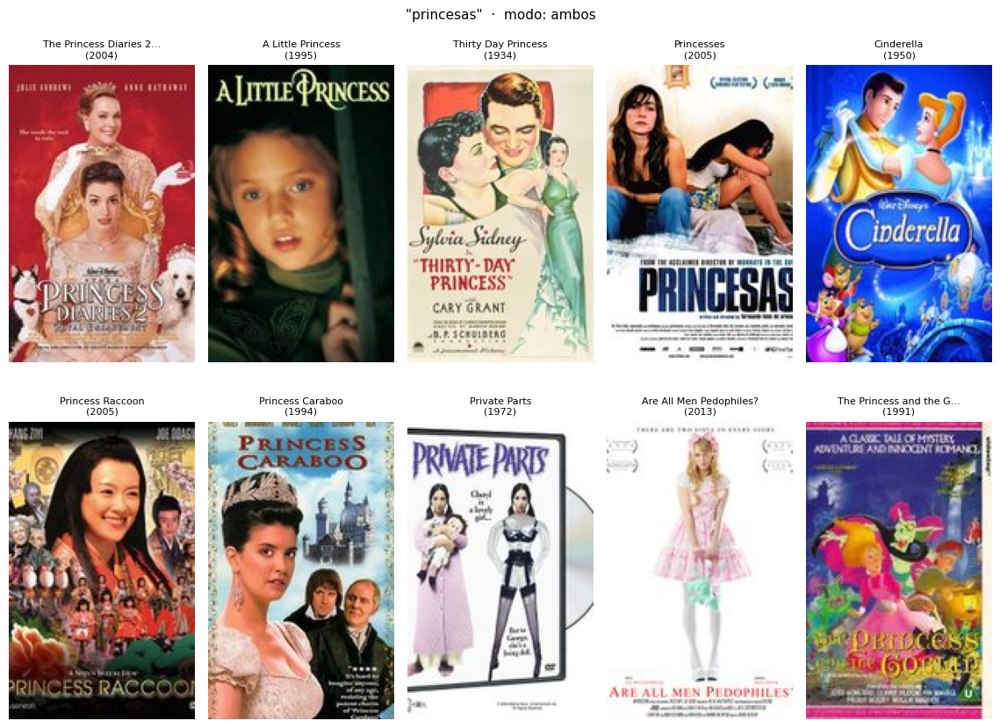

,titulo,anio_txt,generos_imdb_hoy,cos_poster,cos_sinopsis
0,The Princess Diaries 2: Royal Engagement,2004,"Comedy,Family,Romance",0.256,0.857
1,A Little Princess,1995,"Drama,Family,Fantasy",0.258,0.833
2,Thirty Day Princess,1934,"Comedy,Romance",0.253,0.824
3,Princesses,2005,Drama,0.269,0.757
4,Cinderella,1950,"Animation,Family,Fantasy",0.242,0.838
5,Princess Raccoon,2005,"Comedy,Fantasy,Musical",0.241,0.830
6,Princess Caraboo,1994,"Comedy,Drama,History",0.237,0.838
7,Private Parts,1972,"Comedy,Horror,Mystery",0.239,0.833
8,Are All Men Pedophiles?,2013,Documentary,0.249,0.790
9,The Princess and the Goblin,1991,"Adventure,Animation,Comedy",0.217,0.903


In [ ]:
consulta = 'princesas'  #@param {type:"string"}
modo = 'ambos'  #@param ['ambos', 'poster', 'sinopsis']
alfa = 0.5  #@param {type:"slider", min:0, max:1, step:0.1}

res = buscar(consulta, modo=modo, alfa=alfa)
mostrar(res, f'"{consulta}"  ·  modo: {modo}')
res[['titulo', 'anio_txt', 'generos_imdb_hoy', 'cos_poster', 'cos_sinopsis']].round(3)

### ¿Póster, sinopsis o ambos?

La misma búsqueda con los tres modos. Lo que conviene mirar:

- Búsquedas **visuales** ("dibujos animados de colores", "a man with a gun in the dark") deberían ir mejor por póster.
- Búsquedas **de trama** ("un detective investiga un asesinato", "a family moves into an old house") deberían ir mejor por sinopsis.
- ¿`ambos` toma lo mejor de cada uno, o se parece siempre a uno solo?

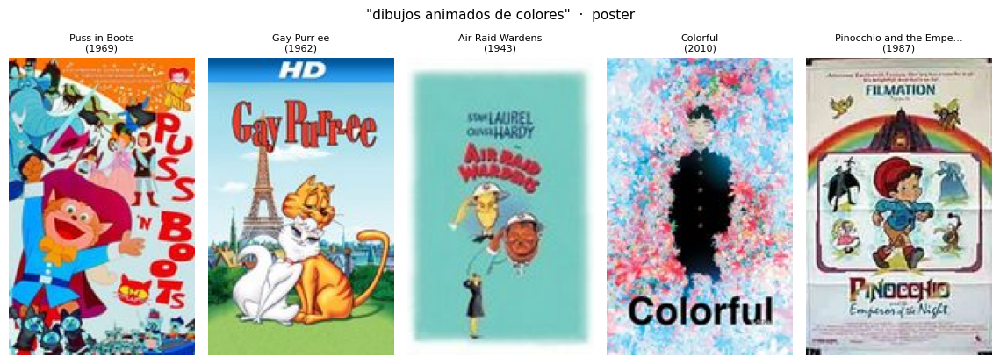

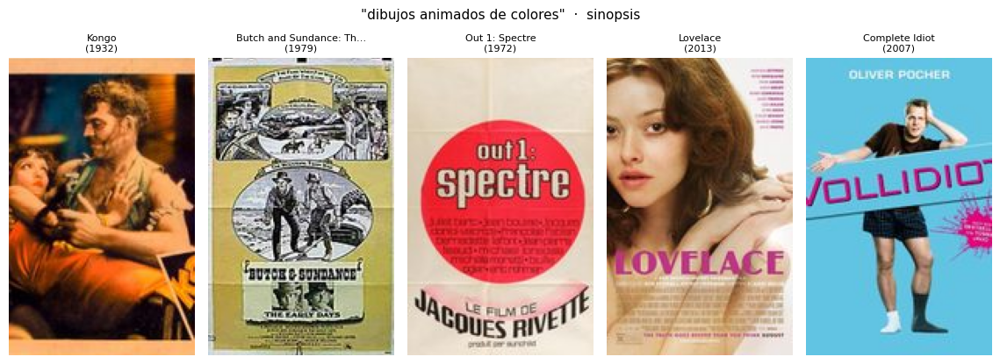

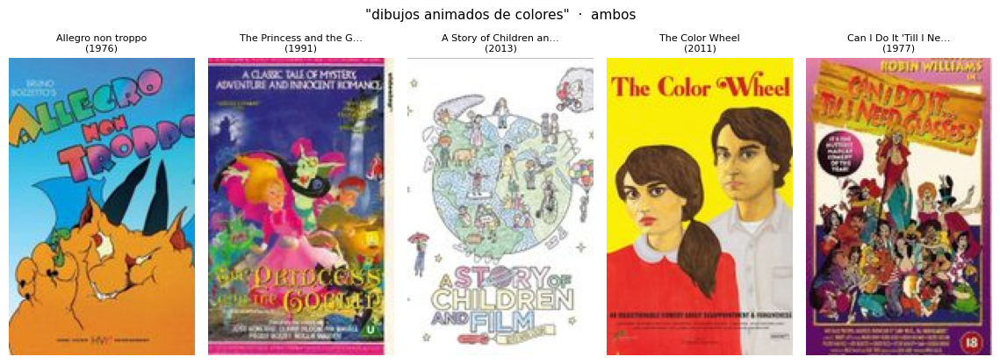

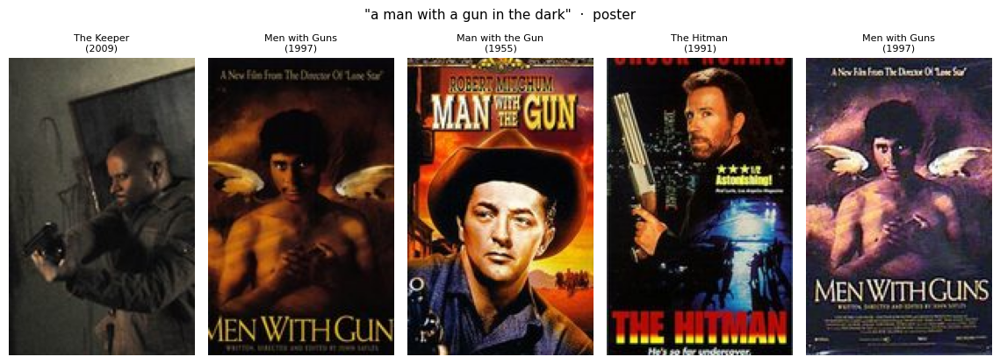

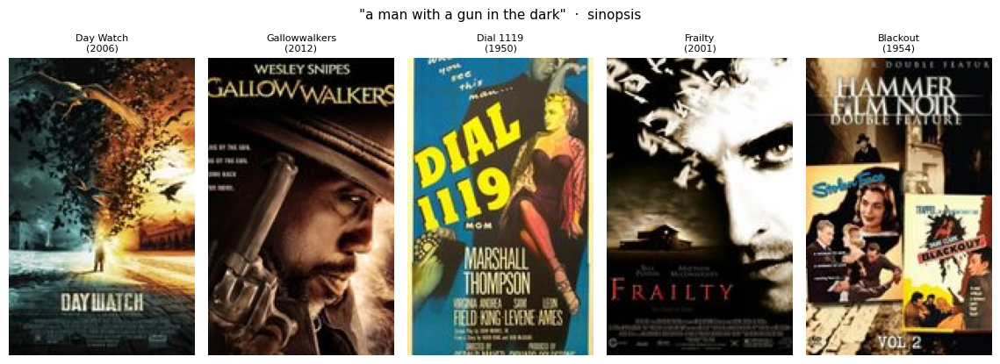

...

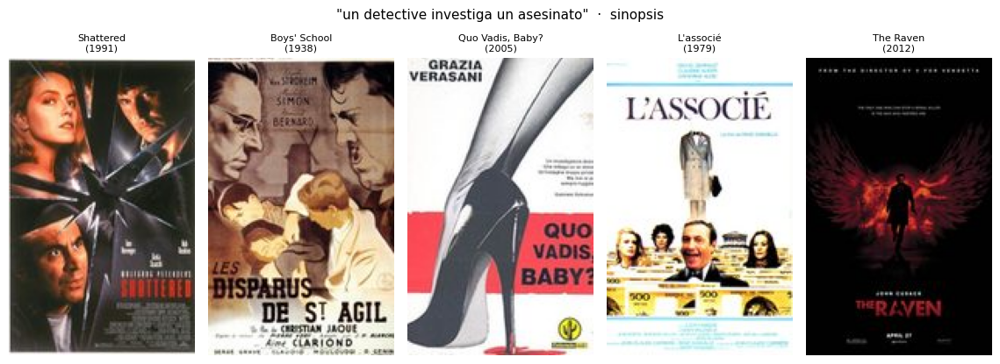

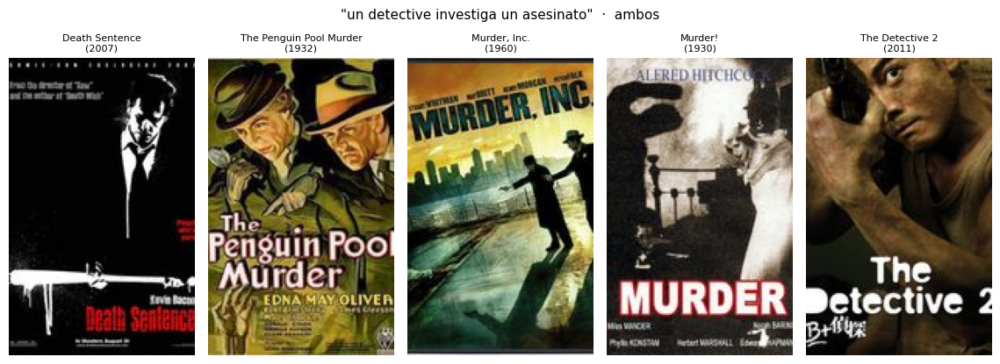

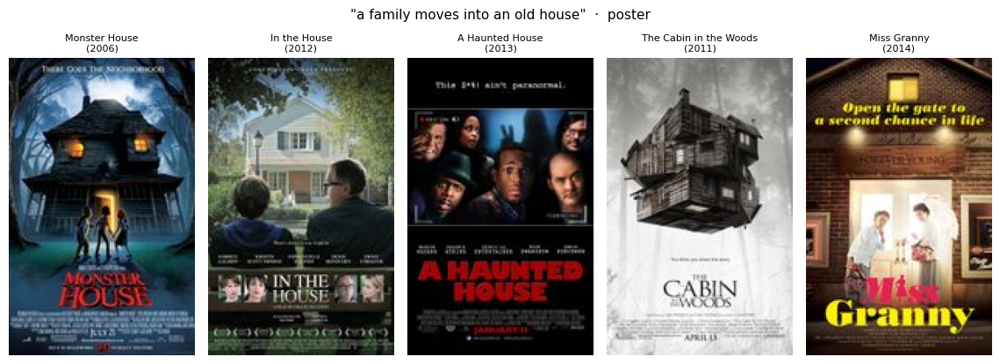

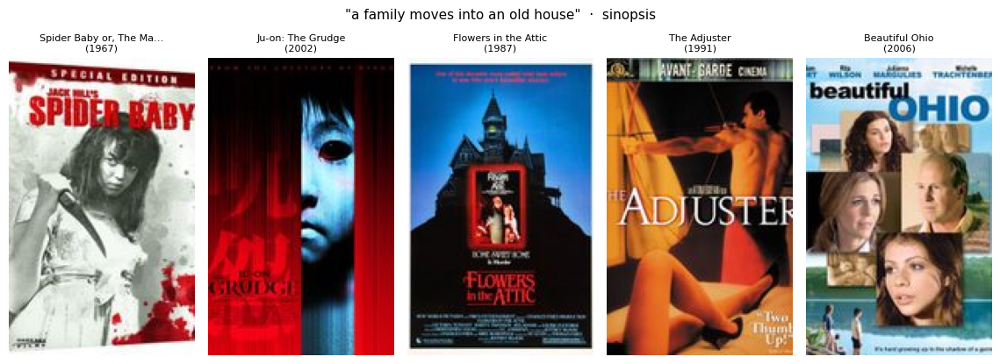

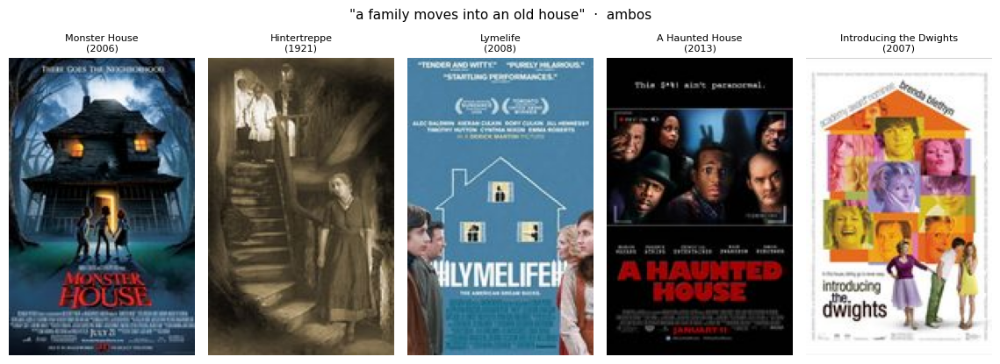

In [ ]:
ejemplos = [
    'dibujos animados de colores',
    'a man with a gun in the dark',
    'un detective investiga un asesinato',
    'a family moves into an old house',
]
for c in ejemplos:
    for m in ['poster', 'sinopsis', 'ambos']:
        mostrar(buscar(c, modo=m, k=5), f'"{c}"  ·  {m}')

## 6. ¿Da lo mismo buscar en español que en inglés?

Para cada par de búsquedas equivalentes se cuentan cuántas de las 20 primeras películas coinciden.
Si el multilingüe funciona bien, la coincidencia debería ser alta.

In [ ]:
pares = [
    ('una película de terror', 'a horror movie'),
    ('una comedia romántica', 'a romantic comedy'),
    ('naves espaciales y robots', 'spaceships and robots'),
    ('vaqueros en el desierto', 'cowboys in the desert'),
    ('dibujos animados para niños', 'cartoons for kids'),
]
filas = []
for es, en in pares:
    fila = {'español': es, 'inglés': en}
    for m in ['poster', 'sinopsis', 'ambos']:
        a = set(buscar(es, modo=m, k=20)['fila_hdf5']); b = set(buscar(en, modo=m, k=20)['fila_hdf5'])
        fila[m] = f'{len(a & b)}/20'
    filas.append(fila)
pd.DataFrame(filas)

,español,inglés,poster,sinopsis,ambos
0,una película de terror,a horror movie,9/20,16/20,12/20
1,una comedia romántica,a romantic comedy,15/20,15/20,15/20
2,naves espaciales y robots,spaceships and robots,14/20,14/20,14/20
3,vaqueros en el desierto,cowboys in the desert,8/20,10/20,11/20
4,dibujos animados para niños,cartoons for kids,12/20,16/20,15/20


## Resumen y siguiente paso

Ya hay un buscador que funciona en español e inglés, sin entrenar nada: CLIP congelado + similitud coseno.

**Lo que dejó este notebook:**

- `data/posters_mini.parquet`: los 25 959 pósters en miniatura (sirve también para la página web).
- La función `buscar(consulta, modo, k, alfa, encoder)`.

**Paso 2 (siguiente notebook):** medir qué tan bien busca. Con búsquedas de género ("una película de terror")
se sabe cuáles respuestas son correctas (las películas con `hoy_Horror = 1`), así que se puede calcular
**precision@10** y **recall@k** para cada modo (póster / sinopsis / ambos), cada idioma y cada codificador.
Eso responde con números la pregunta del proyecto aplicada a la búsqueda: ¿qué ayuda más a encontrar una película,
la imagen o el texto?